In [1]:
# ==================================================
# 1. Importación de librerías
# ==================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.4f}".format)

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

In [2]:
# ==================================================
# 2. Carga de datos
# ==================================================

DATA_FILE = Path("../data/snapshots/aapl_daily_obt.csv")

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"No se encontró el archivo: {DATA_FILE.resolve()}\n"
        "Verifica que aapl_daily_obt.csv esté en "
        "data/snapshots/ dentro del repositorio."
    )

df = pd.read_csv(DATA_FILE)

# Conversión de la fecha a tipo datetime
df["TRADE_DATE"] = pd.to_datetime(df["TRADE_DATE"])

print("Dataset cargado correctamente")
print("-" * 45)
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")
print(f"Fecha inicial: {df['TRADE_DATE'].min()}")
print(f"Fecha final: {df['TRADE_DATE'].max()}")
print(f"Símbolos: {df['SYMBOL'].unique().tolist()}")

display(df.head())

Dataset cargado correctamente
---------------------------------------------
Filas: 4,087
Columnas: 14
Fecha inicial: 2010-07-01 00:00:00
Fecha final: 2026-09-30 00:00:00
Símbolos: ['AAPL']


,DATE_KEY,TRADE_DATE,CALENDAR_YEAR,CALENDAR_QUARTER,MONTH_NUMBER,MONTH_NAME,DAY_OF_MONTH,DAY_OF_WEEK_ISO,DAY_NAME,SYMBOL_KEY,SYMBOL,CLOSE_PRICE,SOURCE,INGESTED_AT
0,20100701,2010-07-01,2010,3,7,Jul,1,4,Thu,1,AAPL,8.8743,Yahoo Finance,2026-11-18 00:03:20.638
1,20100702,2010-07-02,2010,3,7,Jul,2,5,Fri,1,AAPL,8.8193,Yahoo Finance,2026-11-18 00:03:20.638
2,20100706,2010-07-06,2010,3,7,Jul,6,2,Tue,1,AAPL,8.8796,Yahoo Finance,2026-11-18 00:03:20.638
3,20100707,2010-07-07,2010,3,7,Jul,7,3,Wed,1,AAPL,9.2382,Yahoo Finance,2026-11-18 00:03:20.638
4,20100708,2010-07-08,2010,3,7,Jul,8,4,Thu,1,AAPL,9.2175,Yahoo Finance,2026-11-18 00:03:20.638


In [ ]:
# ============================================================
# 3. DIMENSIONES Y ESTRUCTURA
# ============================================================

print("DIMENSIONES DEL DATASET")
print("-" * 50)
print(f"Número de observaciones: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")

print("\nESTRUCTURA DE LAS VARIABLES")
display(
    pd.DataFrame({
        "Tipo de dato": df.dtypes.astype(str),
        "Valores no nulos": df.notna().sum(),
        "Valores nulos": df.isna().sum(),
        "% de nulos": df.isna().mean() * 100
    })
)

: 

In [4]:
# ============================================================
# 4. CALIDAD E INTEGRIDAD DE LOS DATOS
# ============================================================

print("\nREGISTROS DUPLICADOS")
print(
    "Duplicados completos:",
    df.duplicated().sum()
)

print(
    "Duplicados por SYMBOL + TRADE_DATE:",
    df.duplicated(
        subset=["SYMBOL", "TRADE_DATE"]
    ).sum()
)

print("\nVERIFICACIÓN TEMPORAL")
print(f"Fecha mínima: {df['TRADE_DATE'].min()}")
print(f"Fecha máxima: {df['TRADE_DATE'].max()}")
print(
    "Fechas distintas:",
    df["TRADE_DATE"].nunique()
)

print("\nSÍMBOLOS")
display(df["SYMBOL"].value_counts(dropna=False))


REGISTROS DUPLICADOS
Duplicados completos: 0
Duplicados por SYMBOL + TRADE_DATE: 0

VERIFICACIÓN TEMPORAL
Fecha mínima: 2010-07-01 00:00:00
Fecha máxima: 2026-09-30 00:00:00
Fechas distintas: 4087

SÍMBOLOS


SYMBOL
AAPL    4087
Name: count, dtype: int64

In [5]:
# ============================================================
# 5. ESTADÍSTICOS DESCRIPTIVOS
# ============================================================

display(df.describe(include="all").T)

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
DATE_KEY,"4,087.0000",NaN,NaN,NaN,"20,181,795.6966","20,100,701.0000","20,140,723.5000","20,180,813.0000","20,220,901.5000","20,260,930.0000","47,019.9734"
TRADE_DATE,4087,NaN,NaN,NaN,2018-08-13 09:56:30.359676672,2010-07-01 00:00:00,2014-07-23 12:00:00,2018-08-13 00:00:00,2022-09-01 12:00:00,2026-09-30 00:00:00,NaN
CALENDAR_YEAR,"4,087.0000",NaN,NaN,NaN,"2,018.1123","2,010.0000","2,014.0000","2,018.0000","2,022.0000","2,026.0000",4.7046
CALENDAR_QUARTER,"4,087.0000",NaN,NaN,NaN,2.5226,1.0000,2.0000,3.0000,3.0000,4.0000,1.1075
MONTH_NUMBER,"4,087.0000",NaN,NaN,NaN,6.5689,1.0000,4.0000,7.0000,9.0000,12.0000,3.4070
MONTH_NAME,4087,12,Aug,376,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DAY_OF_MONTH,"4,087.0000",NaN,NaN,NaN,15.7357,1.0000,8.0000,16.0000,23.0000,31.0000,8.7544
DAY_OF_WEEK_ISO,"4,087.0000",NaN,NaN,NaN,3.0225,1.0000,2.0000,3.0000,4.0000,5.0000,1.3994
DAY_NAME,4087,5,Tue,841,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SYMBOL_KEY,"4,087.0000",NaN,NaN,NaN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000


In [6]:
# Estadística descriptiva del Precio de Cierre
close_stats = df["CLOSE_PRICE"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame("CLOSE_PRICE")

display(close_stats)

print("Asimetría:", df["CLOSE_PRICE"].skew())
print("Curtosis:", df["CLOSE_PRICE"].kurtosis())

,CLOSE_PRICE
count,"4,087.0000"
mean,91.6246
std,85.1613
min,8.5689
1%,9.3427
5%,12.3268
25%,23.7539
50%,44.7250
75%,157.3600
95%,259.0340


Asimetría: 0.9277003497489581
Curtosis: -0.34708459368652234


Esto sugiere, con la diferencia de mediana y media, que la distribución tiene asimetría positiva. L desviación estándar respecto a la media es muy alta, pero se puede esperar de data que crece en el largo plazo.

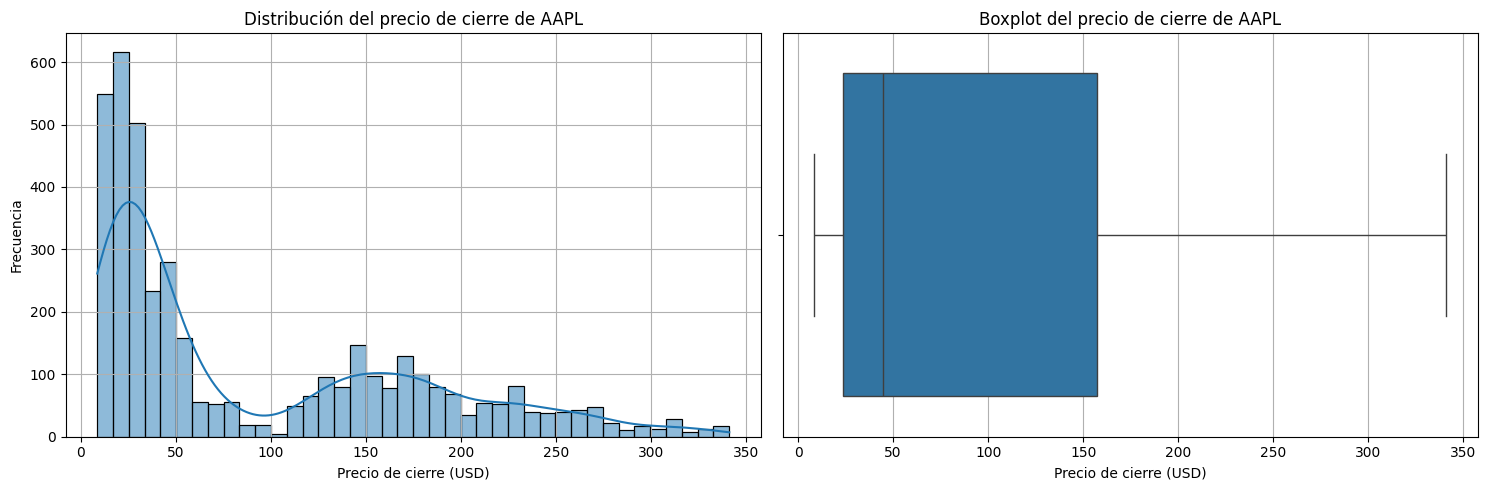

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histograma
sns.histplot(
    data=df,
    x="CLOSE_PRICE",
    bins=40,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribución del precio de cierre de AAPL")
axes[0].set_xlabel("Precio de cierre (USD)")
axes[0].set_ylabel("Frecuencia")

# Boxplot
sns.boxplot(
    data=df,
    x="CLOSE_PRICE",
    ax=axes[1]
)

axes[1].set_title("Boxplot del precio de cierre de AAPL")
axes[1].set_xlabel("Precio de cierre (USD)")

plt.tight_layout()
plt.show()

In [8]:
# ---------------------------------------------
# 1. Método IQR
# ---------------------------------------------

Q1 = df["CLOSE_PRICE"].quantile(0.25)
Q3 = df["CLOSE_PRICE"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = df[
    (df["CLOSE_PRICE"] < lower_bound) |
    (df["CLOSE_PRICE"] > upper_bound)
]

print("MÉTODO IQR")
print(f"Q1: {Q1:.4f}")
print(f"Q3: {Q3:.4f}")
print(f"IQR: {IQR:.4f}")
print(f"Límite inferior: {lower_bound:.4f}")
print(f"Límite superior: {upper_bound:.4f}")
print(f"Valores atípicos: {len(outliers_iqr)}")


# ---------------------------------------------
# 2. Método Z-score
# ---------------------------------------------

z_scores = stats.zscore(
    df["CLOSE_PRICE"],
    nan_policy="omit"
)

outliers_z = df[np.abs(z_scores) >= 3]

print("\nMÉTODO Z-SCORE")
print("Umbral: |Z| >= 3")
print(f"Valores atípicos: {len(outliers_z)}")

MÉTODO IQR
Q1: 23.7539
Q3: 157.3600
IQR: 133.6061
Límite inferior: -176.6552
Límite superior: 357.7691
Valores atípicos: 0

MÉTODO Z-SCORE
Umbral: |Z| >= 3
Valores atípicos: 0


No hay criterio estadístico (entre ambos métodos) que nos indique que se debería eliminar puntos críticos.

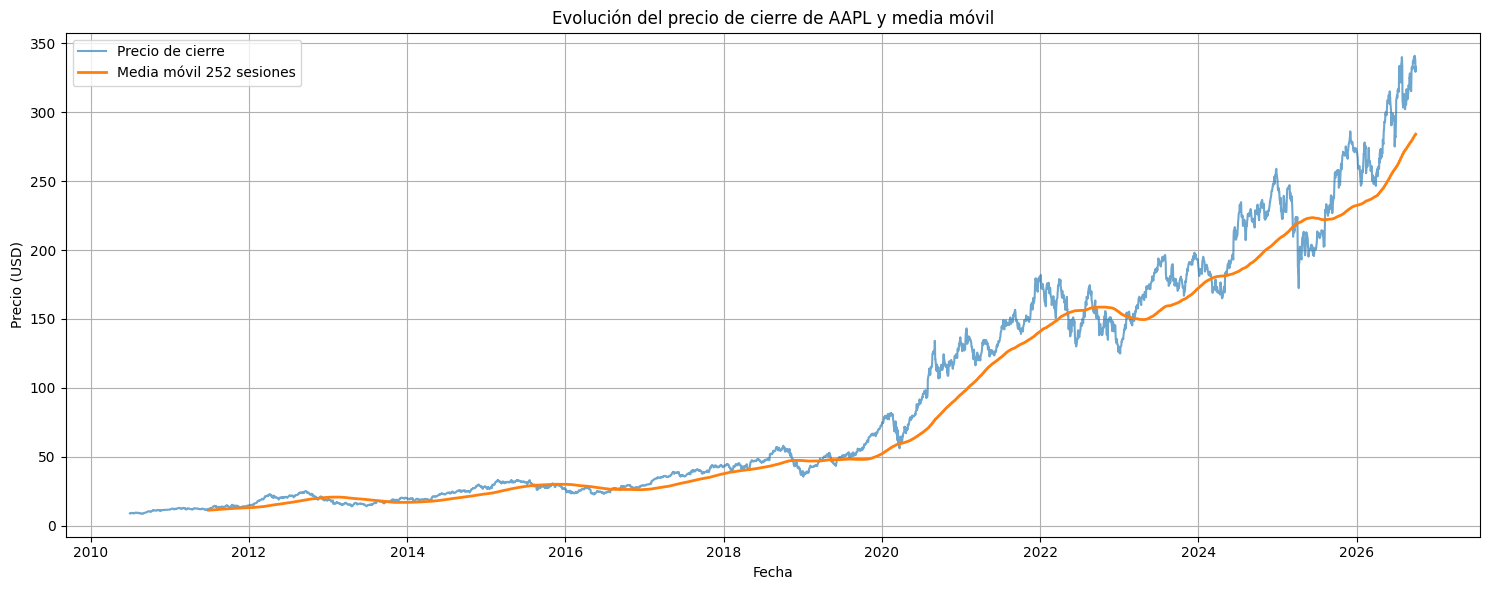

In [9]:
#Evolución y tendencia con media móvil
#  Ordenar cronológicamente
df = df.sort_values("TRADE_DATE").copy()

# Media móvil de 252 sesiones
df["SMA_252"] = df["CLOSE_PRICE"].rolling(
    window=252
).mean()

# Gráfico
plt.figure(figsize=(15, 6))

plt.plot(
    df["TRADE_DATE"],
    df["CLOSE_PRICE"],
    label="Precio de cierre",
    alpha=0.65
)

plt.plot(
    df["TRADE_DATE"],
    df["SMA_252"],
    label="Media móvil 252 sesiones",
    linewidth=2
)

plt.title("Evolución del precio de cierre de AAPL y media móvil")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.tight_layout()
plt.show()

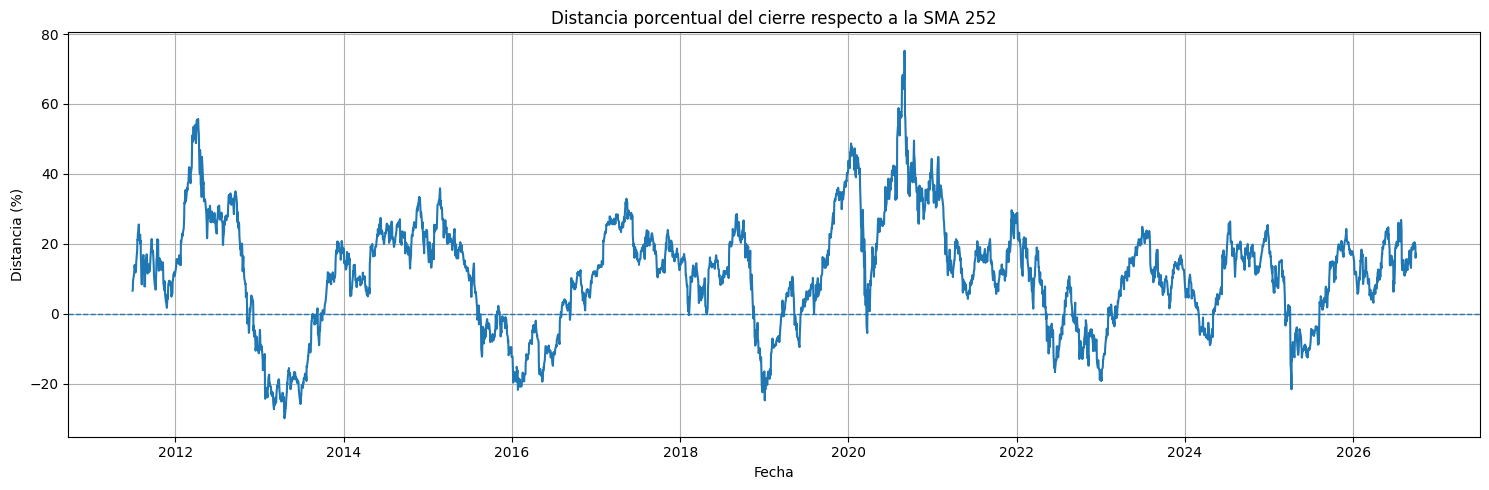

In [10]:
#Diferencia de mdeia movil
df["DIST_SMA_252"] = (
    (df["CLOSE_PRICE"] / df["SMA_252"]) - 1
) * 100

plt.figure(figsize=(15, 5))

plt.plot(
    df["TRADE_DATE"],
    df["DIST_SMA_252"]
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("Distancia porcentual del cierre respecto a la SMA 252")
plt.xlabel("Fecha")
plt.ylabel("Distancia (%)")
plt.tight_layout()
plt.show()

La media móvil ensuaviza y quita ruido, y se logra ver mejor la tendencia. Se puede ver un crecimiento más pronunciado después del 2020. La distancia respecto a la media movil muestra que en general el precio permanece por encima de la media movil. 

,mean,median,std,count
DAY_NAME,,,,
Mon,0.2885,0.3477,1.8454,765
Tue,0.1605,0.1292,1.6470,841
Wed,0.1743,0.1141,1.8102,838
Thu,-0.0635,-0.0496,1.7549,822
Fri,-0.0285,-0.0391,1.7432,820


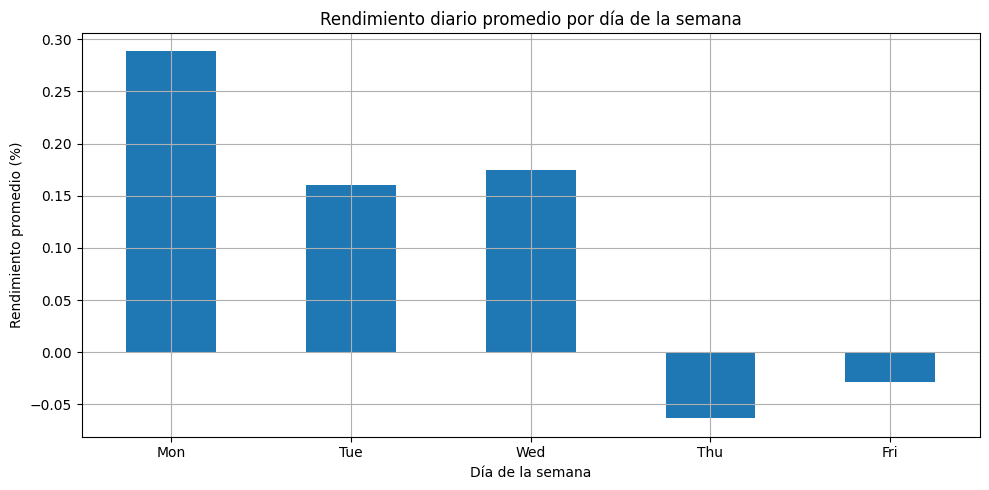

In [11]:
df["RETURN"] = df["CLOSE_PRICE"].pct_change() * 100

# Día de la semana
weekly_returns = (
    df.groupby("DAY_NAME")["RETURN"]
    .agg(["mean", "median", "std", "count"])
)

day_order = ["Mon", "Tue", "Wed", "Thu", "Fri"]

weekly_returns = weekly_returns.reindex(day_order)

display(weekly_returns)

weekly_returns["mean"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Rendimiento diario promedio por día de la semana"
)

plt.xlabel("Día de la semana")
plt.ylabel("Rendimiento promedio (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

,mean,median,std,count
MONTH_NUMBER,,,,
1,0.0088,0.0468,2.0652,324
2,0.1160,0.1233,1.5876,307
3,0.0820,0.0905,2.1896,349
4,0.0615,0.0100,2.1491,331
5,0.1418,0.0440,1.6289,339
6,0.0476,0.0398,1.4813,337
7,0.3209,0.2895,1.5303,359
8,0.1962,0.1708,1.6878,376
9,-0.0098,0.0888,1.7938,348


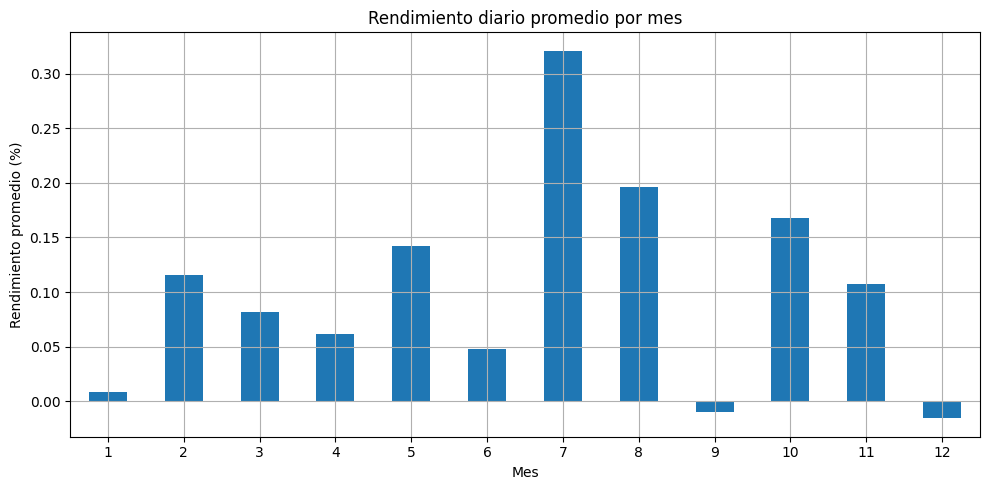

In [12]:
monthly_returns = (
    df.groupby("MONTH_NUMBER")["RETURN"]
    .agg(["mean", "median", "std", "count"])
)

display(monthly_returns)

monthly_returns["mean"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Rendimiento diario promedio por mes"
)

plt.xlabel("Mes")
plt.ylabel("Rendimiento promedio (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Aquí se pueden ver patrones interesantes, como que los mayores rendimientos son en lunes, aunque no muestra diferencia estadística significativa con los otros días con rednimiento positivo.Y el jueves y el viernes tienen rendimientos promedio negativos. Además que en julio hay el mayor rendimiento diario y en septiembre y diciembre en general es negativo. 

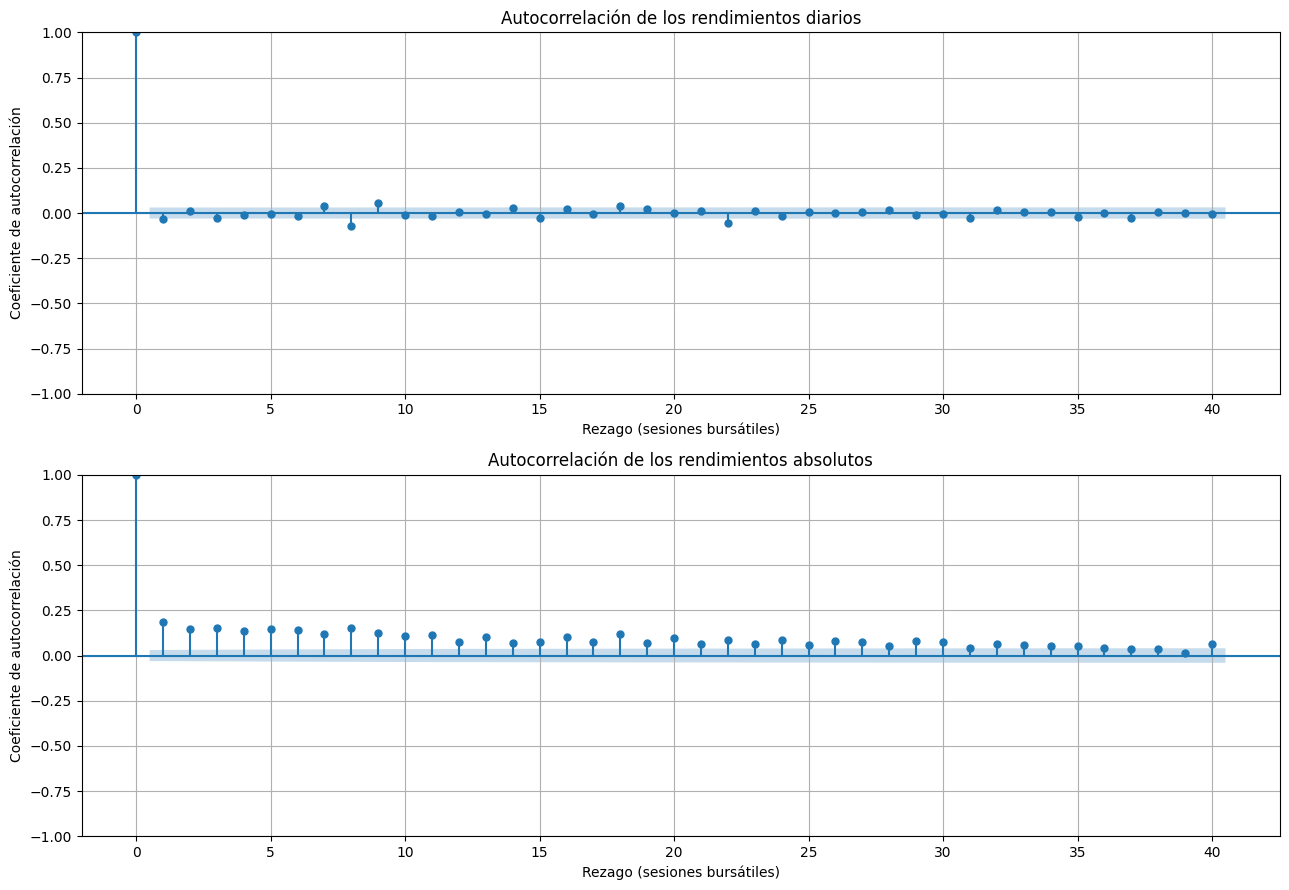

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Autocorrelación de los rendimientos diarios
plot_acf(
    df["RETURN"].dropna(),
    lags=40,
    ax=axes[0]
)
axes[0].set_title("Autocorrelación de los rendimientos diarios")
axes[0].set_xlabel("Rezago (sesiones bursátiles)")
axes[0].set_ylabel("Coeficiente de autocorrelación")

# Autocorrelación de los rendimientos absolutos
plot_acf(
    df["RETURN"].abs().dropna(),
    lags=40,
    ax=axes[1]
)
axes[1].set_title("Autocorrelación de los rendimientos absolutos")
axes[1].set_xlabel("Rezago (sesiones bursátiles)")
axes[1].set_ylabel("Coeficiente de autocorrelación")

plt.tight_layout()
plt.show()

Se identifican valores de autocorrelación que sobresalen de las bandas de confianza en los lags 7, 8, 9 y 22. La autocorrelación tiende a aproximarse a cero conforme aumenta el rezago, lo que sugiere una dependencia lineal limitada y localizada en determinados rezagos.
se observa un mayor número de rezagos con autocorrelaciones fuera de las bandas de confianza, lo que evidencia persistencia temporal en la magnitud de los rendimientos. Este comportamiento podría ser compatible con el fenómeno de agrupamiento de volatilidad.

In [14]:
#ESTACIONAREIDAD

from statsmodels.tsa.stattools import adfuller, kpss

def evaluar_estacionariedad(serie, nombre):
    serie = serie.dropna()

    # Prueba ADF
    resultado_adf = adfuller(serie, autolag="AIC")

    # Prueba KPSS
    resultado_kpss = kpss(
        serie,
        regression="c",
        nlags="auto"
    )

    return {
        "Variable": nombre,
        "ADF estadístico": resultado_adf[0],
        "ADF p-value": resultado_adf[1],
        "KPSS estadístico": resultado_kpss[0],
        "KPSS p-value": resultado_kpss[1]
    }


resultados = pd.DataFrame([
    evaluar_estacionariedad(df["CLOSE_PRICE"], "CLOSE_PRICE"),
    evaluar_estacionariedad(df["RETURN"], "RETURN")
])

display(resultados)

C:\Users\usuario\AppData\Local\Temp\ipykernel_6696\2157015769.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie, autolag="AIC")
C:\Users\usuario\AppData\Local\Temp\ipykernel_6696\2157015769.py:12: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  resultado_kpss = kpss(
C:\Users\usuario\AppData\Local\Temp\ipykernel_6696\2157015769.py:12: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whic

,Variable,ADF estadístico,ADF p-value,KPSS estadístico,KPSS p-value
0,CLOSE_PRICE,2.0198,0.9987,9.0432,0.0100
1,RETURN,-21.5247,0.0000,0.0393,0.1000


ADF. Hipótesis nula: l serie tiene raíz unitaria (no es estaconaria)

KPSS. Hipótesis nula: La serie es estaconaria alrededor de una constante.

Close Price: 
En ADF se acepta la hipótesis nula y en KPSS se rechaza. Es decir que no hay estacionareidad

Return:
ADF se rechaza hipótesis nula y en KPSS se rechaza con un nivel de significancia del 5%. Cómo también se vio en las autocorrelaciones.

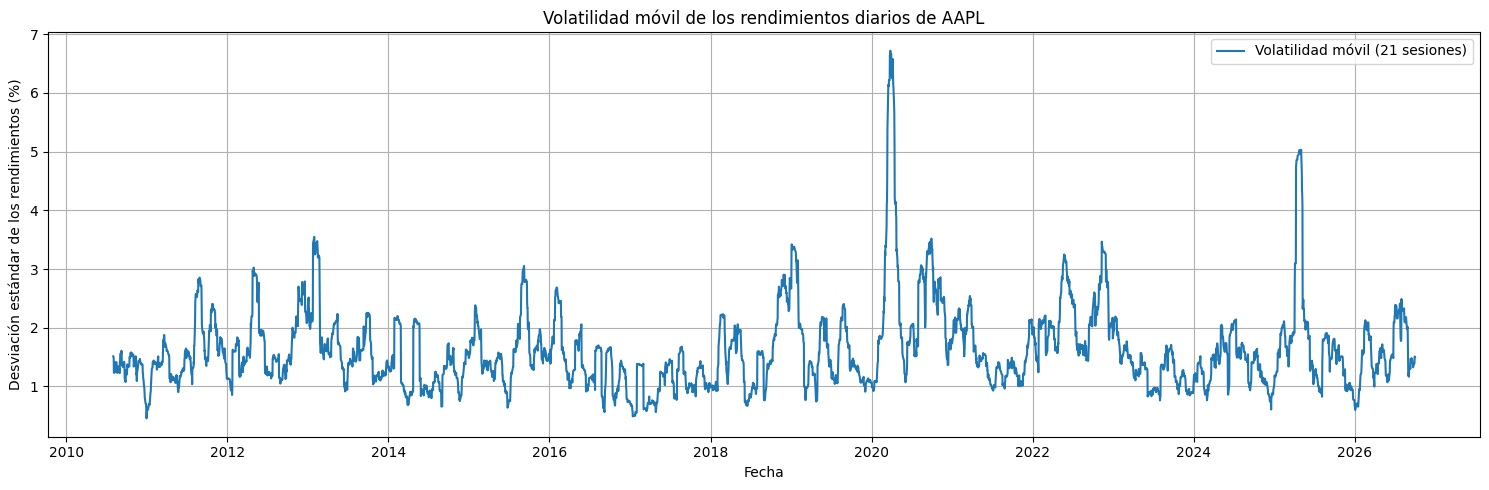

In [15]:
# Volatilidad móvil de 21 sesiones
df["VOLATILITY_21"] = df["RETURN"].rolling(window=21).std()

# Gráfica
plt.figure(figsize=(15, 5))

plt.plot(
    df["TRADE_DATE"],
    df["VOLATILITY_21"],
    label="Volatilidad móvil (21 sesiones)"
)

plt.title("Volatilidad móvil de los rendimientos diarios de AAPL")
plt.xlabel("Fecha")
plt.ylabel("Desviación estándar de los rendimientos (%)")
plt.legend()
plt.tight_layout()
plt.show()

Aquí se calculó volatilidad móvil donde se ven dos picos sumamente pronunciados de volatilidad. Fuera de esto no parece haber cmabio de mucha magnitud.

In [ ]:
#Distribución de rendimientos
return_stats = df["RETURN"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame("RETURN")

display(return_stats)

print("Asimetría:", df["RETURN"].skew())
print("Curtosis:", df["RETURN"].kurtosis())

,RETURN
count,"4,086.0000"
mean,0.1043
std,1.7639
min,-12.8647
1%,-4.7542
5%,-2.6445
25%,-0.7410
50%,0.0916
75%,1.0144
95%,2.7644


Asimetría: 0.03947909148564874
Curtosis: 6.2518767197842555


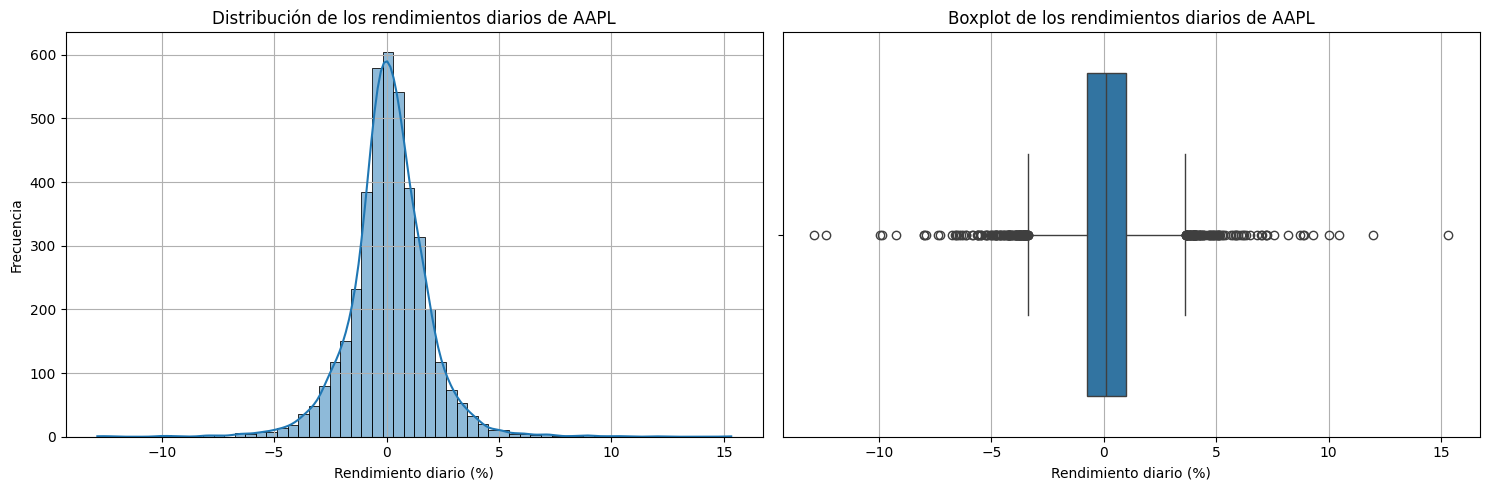

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(
    data=df,
    x="RETURN",
    bins=60,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Distribución de los rendimientos diarios de AAPL")
axes[0].set_xlabel("Rendimiento diario (%)")
axes[0].set_ylabel("Frecuencia")

sns.boxplot(
    data=df,
    x="RETURN",
    ax=axes[1]
)

axes[1].set_title("Boxplot de los rendimientos diarios de AAPL")
axes[1].set_xlabel("Rendimiento diario (%)")

plt.tight_layout()
plt.show()

Se ve un comportamiento bastante simétrico con colas largas, es decir que hay rendimientos bastante fuera de la media. 

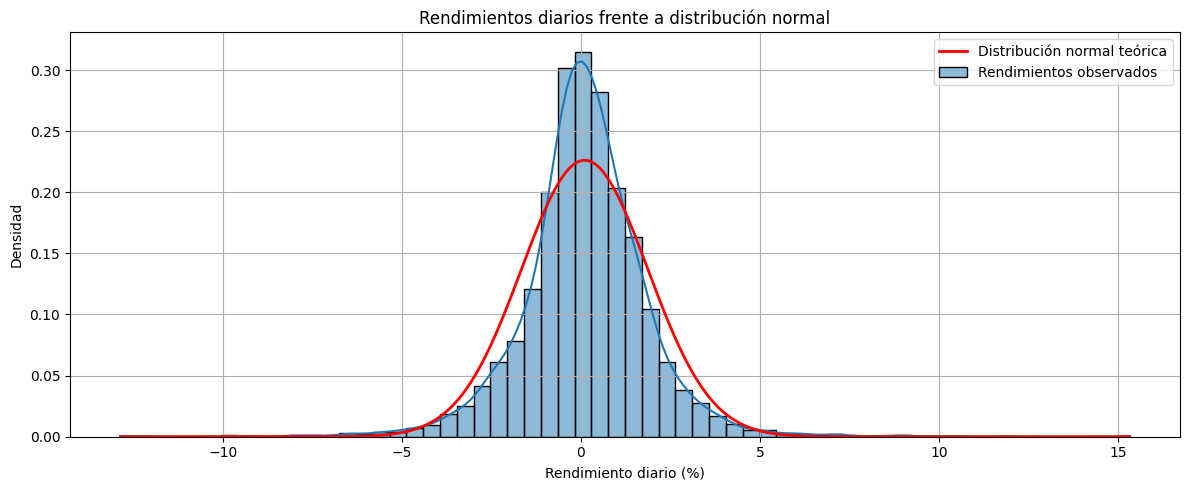

In [19]:
from scipy.stats import norm

plt.figure(figsize=(12, 5))

sns.histplot(
    df["RETURN"].dropna(),
    bins=60,
    stat="density",
    kde=True,
    label="Rendimientos observados"
)

x = np.linspace(
    df["RETURN"].min(),
    df["RETURN"].max(),
    500
)

plt.plot(
    x,
    norm.pdf(
        x,
        loc=df["RETURN"].mean(),
        scale=df["RETURN"].std()
    ),
    label="Distribución normal teórica",
    linewidth=2, c="r"
)

plt.title("Rendimientos diarios frente a distribución normal")
plt.xlabel("Rendimiento diario (%)")
plt.ylabel("Densidad")
plt.legend()
plt.tight_layout()
plt.show()